In [1]:
import os
import hydra
from omegaconf import OmegaConf, DictConfig

import torch
import lightning as L
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint

from rl4co.utils.trainer import RL4COTrainer
from rl4co.envs import get_env

from models.zoo.icam.model import ICAM

cfg = OmegaConf.load('./configs/icam.yaml')

L.seed_everything(cfg.get("seed", 1234))

env_params = cfg.env
model_params_dict = OmegaConf.to_container(cfg.model, resolve=True)
if env_params.env_name == "shpp":
    from envs.routing.shpp.env import SHPPEnv
    from models.nn.env_embeddings.init import SHPPInitEmbedding
    from models.nn.env_embeddings.context import SHPPContext
    from rl4co.models.nn.env_embeddings.dynamic import StaticEmbedding
    del env_params.env_name
    env = SHPPEnv(**env_params)
    
    model_params_dict['policy_kwargs'].update({
        "init_embedding": SHPPInitEmbedding(embed_dim=cfg.embed_dim),
        "context_embedding": SHPPContext(embed_dim=cfg.embed_dim),
        "dynamic_embedding": StaticEmbedding(),
    })
else:
    env = get_env(**env_params)

if model_params_dict['policy_kwargs']['pointer'] == "poly":
    from rl4co.models.nn.attention import PolyNetAttention
    model_params_dict['policy_kwargs']['pointer'] = PolyNetAttention(
        **cfg.poly, 
        poly_layer_dim=cfg.embed_dim*2
    )

if model_params_dict['policy_kwargs']['encoder'] == "am":
    from rl4co.models.zoo.am.encoder import AttentionModelEncoder
    model_params_dict['policy_kwargs']['encoder'] = AttentionModelEncoder(
        embed_dim=cfg.embed_dim,
        num_heads=cfg.num_heads,
        num_layers=model_params_dict['policy_kwargs']['num_encoder_layers'],
        normalization=model_params_dict['policy_kwargs']['normalization'],
    )

model = ICAM(
    env=env,
    **model_params_dict,
)

/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torchrl/data/replay_buffers/samplers.py:37: UserWarning: Failed to import torchrl C++ binaries. Some modules (eg, prioritized replay buffers) may not work with your installation. If you installed TorchRL from PyPI, please report the bug on TorchRL github. If you installed TorchRL locally and/or in development mode, check that you have all the required compiling packages.
  warnings.warn(EXTENSION_WARNING)
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/cpz/anaconda3/envs/rl4co/lib/python3.12/site-packages/torch/jit/frontend.py:1209: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  elif isinstance(value, ast.Str):
/home/cpz/anaconda3/envs/rl4co/lib/pytho

In [2]:
ckpt_path = 'outputs/checkpoints/icam-shpp50-80polyNone/last.ckpt'
ckpt_state_dict = torch.load(ckpt_path)['state_dict']
model.load_state_dict(ckpt_state_dict)

<All keys matched successfully>

Problem 1 | Cost: 6.193
Problem 2 | Cost: 6.558
Problem 3 | Cost: 6.530


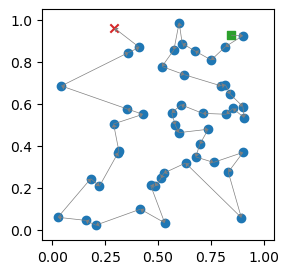

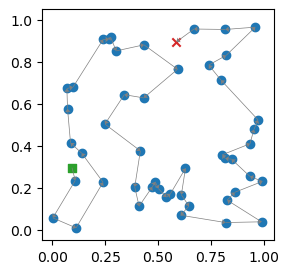

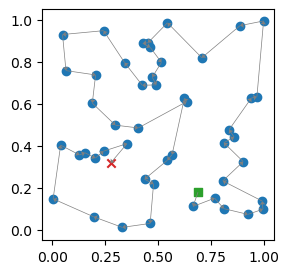

In [3]:
device = "cpu"
n_samples = 3
td_init = env.reset(batch_size=[n_samples]).to(device)
policy = model.policy.to(device)

out = policy(td_init.clone(), env=env, phase="test", decode_type="sampling",
             multisample=True, num_starts=80, return_actions=True)
actions = out['actions'].cpu().detach()
rewards = out['reward'].cpu().detach()

for i in range(3):
    print(f"Problem {i+1} | Cost: {-rewards[i]:.3f}")
    env.render(td_init[i], actions[i])

In [4]:
improved_actions = env.local_search(td_init, actions)
improved_rewards = env.get_reward(td_init, improved_actions)

for i in range(3):
    print(f"Problem {i+1} | Improved Cost: {-improved_rewards[i]:.3f}")
    env.render(td_init[i], improved_actions[i])

NotImplementedError: Local is not implemented yet for shpp environment